### Imports

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks, savgol_filter
import seaborn as sns

#### _Notes:_ Van der Pol System

The Van der Pol system we will first look at is the following:
$$\dot{x} = y$$
$$\dot{y} = \mu(1-x^2)y-x$$

#### Define Deterministic Trajectory

Functions: `vanderpol(t, z, mu, is_inverted)`, `solve_vanderpol(x0, y0, T, dt, mu, is_inverted)`

In [37]:
def vanderpol(t, z, mu, is_inverted):

    """
    Function Inputs:
    t               = Current time
    z               = Current coordinate pair [x,y]
    mu              = Van der Pol parameter
    is_inverted     = if True, make the system time-reversed

    Function Outputs:
    [dxdt, dydt]    = Van der Pol oscillator first derivative values
    
    """

    x, y = z
    dxdt = y
    dydt = mu * (1 - x**2) * y - x

    if is_inverted:
        dxdt *= -1
        dydt *= -1
    
    return [dxdt, dydt]

def solve_vanderpol(x0, y0, T, dt, mu, is_inverted):
    
    """
    Function Inputs:
    x0              = Initial condition of x
    y0              = Initial condition of y
    T               = Total time amount (e.g. 1 year)
    dt              = Size of time step
    mu              = Van der Pol parameter
    is_inverted     = if True, make the system time-reversed

    Function Outputs:
    t               = Array of time points
    x               = Simulated x values
    y               = Simulated y values
    
    """
    
    N = int(T / dt)
    t_span = (0, T)
    t = np.linspace(0, T, N + 1)

    trajectory = solve_ivp(vanderpol, t_span, [x0, y0], args=(mu, is_inverted), t_eval=t)

    x = trajectory.y[0]
    y = trajectory.y[1]

    return t, x, y

#### _Notes:_ The Noisy Van der Pol System

The next step in evaluating the Van der Pol oscillator is to introduce additive noise to the system. To model such a system, we will use the Euler-Murayama method to discretize the system and plot randomly-induced tipping points. The Euler scheme for the Van der Pol system is as follows:
$$x_{n+1} = x_{n}+ y \Delta t + \sigma_1 \sqrt{\Delta t} N(0,1)$$
$$y_{n+1} = y_n + (\mu(1-x^2)y-x) \Delta t + \sigma_2 \sqrt{\Delta t} N(0,1)$$
where $\sigma_1, \sigma_2 > 0$ denote noise strength.

#### Define Euler-Maruyama Method

Function: `euler_murayama(x0, y0, T, dt, mu, sigma1, sigma2, is_inverted)`

In [38]:
def euler_maruyama(x0, y0, T, dt, mu, sigma1, sigma2, is_inverted):

    """
    Function Inputs:
    y0              = Initial condition of y
    x0              = Initial condition of x
    T               = Total time amount (e.g. 1 year)
    dt              = Size of time steps
    mu              = Van der Pol parameter
    sigma1          = Noise strength parameter for x
    sigma2          = Noise strength parameter for y
    is_inverted     = if True, make the system time-reversed

    Function Outputs:
    t               = Array of time points
    x               = Simulated x values
    y               = Simulated y values
    
    """
    N = int(T / dt)
    t = np.linspace(0, T, N + 1)
    x = np.zeros(N + 1) 
    y = np.zeros(N + 1)

    # Set initial conditions
    x[0] = x0
    y[0] = y0

    # Draw random variables for additive noise
    x_noise = np.random.normal(0, 1, N)
    y_noise = np.random.normal(0, 1, N)

    for n in range(N):

        # Numerically simulate change in Weiner process
        dW1 = np.sqrt(dt) * x_noise[n]
        dW2 = np.sqrt(dt) * y_noise[n]

        # Call Van der Pol function
        f1, f2 = vanderpol(t[n], [x[n], y[n]], mu, is_inverted)

        # Euler-Murayama update
        x[n+1] = x[n] + f1 * dt + sigma1 * dW1
        y[n+1] = y[n] + f2 * dt + sigma2 * dW2

    return t, x, y

### Plotting the Oscillator's Behavior

In [58]:
mu              = 0.5       # Van der Pol parameter, keep mu > 0
sigma1          = 0.1      # Noise strength for x
sigma2          = 0.1      # Noise strength for y
x0              = 0.1       # Initial x value
y0              = 0.1       # Initial y value
T               = 100      # Total amount of time
dt              = 0.1     # Time step size
is_inverted     = False     # Flag for time reversal of system

In [59]:
# Run the Van der Pol oscillator without noise
time_grid_det, deterministic_x, deterministic_y = solve_vanderpol(x0, y0, T, dt, mu, is_inverted)

# Run the simulation with noise
time_grid_sim, simulated_x, simulated_y = euler_maruyama(x0, y0, T, dt, mu, sigma1, sigma2, is_inverted)

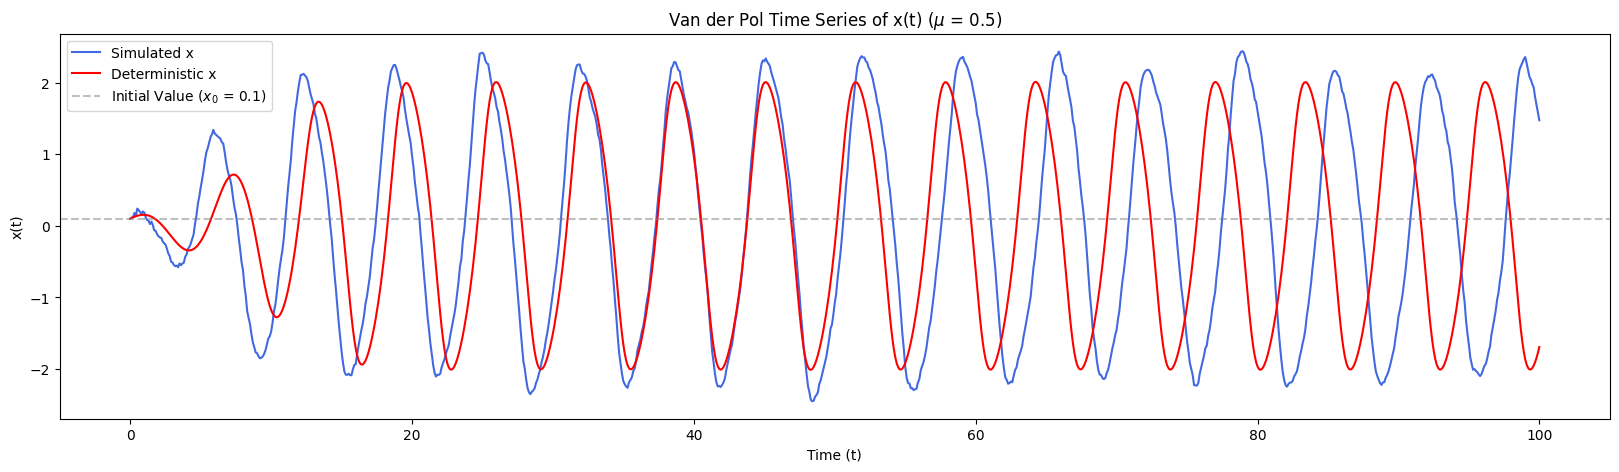

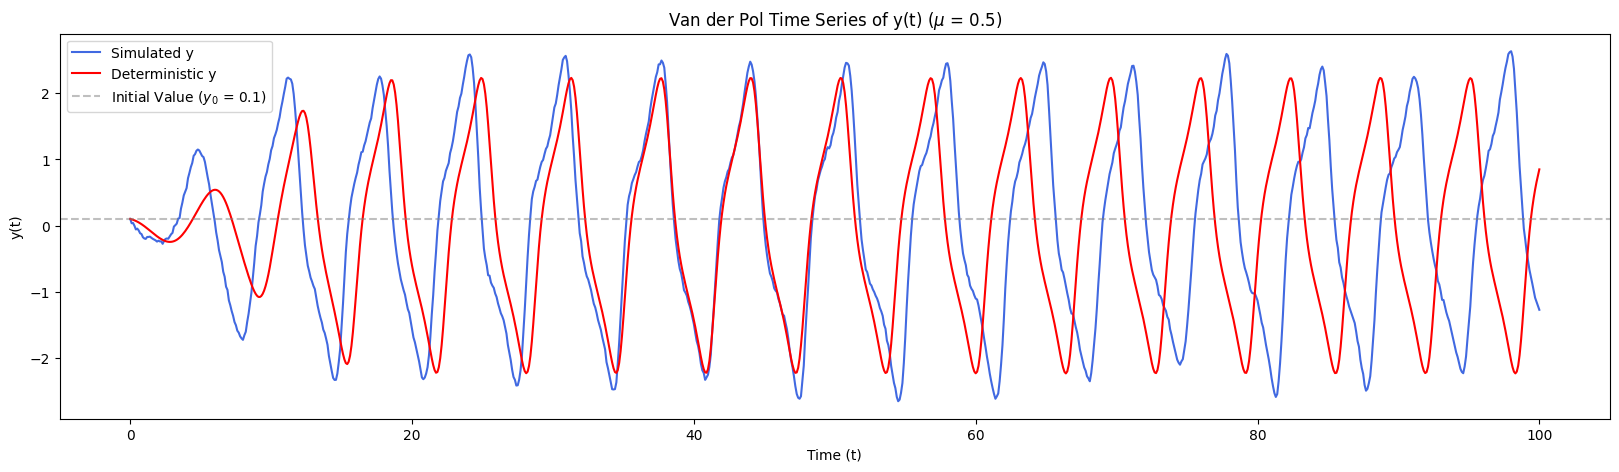

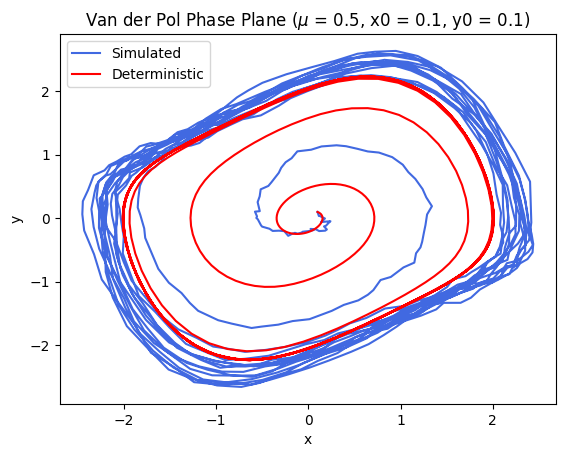

In [60]:
# Plot time-series of x
plt.figure(figsize=(20, 5))
plt.plot(time_grid_sim, simulated_x, label="Simulated x", color="royalblue", lw=1.5)
plt.plot(time_grid_det, deterministic_x, label="Deterministic x", color="red", lw=1.5)
plt.axhline(x0, color="gray", linestyle="--", alpha=0.5, label=f"Initial Value ($x_0$ = {x0})")

plt.title(fr"Van der Pol Time Series of x(t) ($\mu$ = {mu})", fontsize=12)
plt.xlabel("Time (t)")
plt.ylabel("x(t)")
plt.legend(loc="upper left")


# Plot time-series of y
plt.figure(figsize=(20, 5))
plt.plot(time_grid_sim, simulated_y, label="Simulated y", color="royalblue", lw=1.5)
plt.plot(time_grid_det, deterministic_y, label="Deterministic y", color="red", lw=1.5)
plt.axhline(y0, color="gray", linestyle="--", alpha=0.5, label=f"Initial Value ($y_0$ = {y0})")

plt.title(fr"Van der Pol Time Series of y(t) ($\mu$ = {mu})", fontsize=12)
plt.xlabel("Time (t)")
plt.ylabel("y(t)")
plt.legend(loc="upper left")


# Plot phase plane
plt.figure()
plt.plot(simulated_x, simulated_y, label="Simulated", color="royalblue", lw=1.5)
plt.plot(deterministic_x, deterministic_y, label="Deterministic", color="red", lw=1.5)

plt.title(fr"Van der Pol Phase Plane ($\mu$ = {mu}, x0 = {x0}, y0 = {y0})", fontsize=12)
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="upper left")


# Show plots
plt.show()

### Defining Functions for Parameter Testing

#### Define Spaghetti Strand Function

Function: `spaghetti_strands(x0, y0, T, N, mu, sigma1, sigma2, is_inverted, S)`

Returns: `strands_time`, `strands_x`, `strands_y`

In [8]:
def spaghetti_strands(x0, y0, T, dt, mu, sigma1, sigma2, is_inverted, S):

    """
    Function Inputs:
    y0              = Initial condition of y
    x0              = Initial condition of x
    T               = Total time amount (e.g. 1 year)
    dt              = Size of time steps
    mu              = Van der Pol parameter
    sigma1          = Noise strength parameter for x
    sigma2          = Noise strength parameter for y
    is_inverted     = if True, make the system time-reversed
    S               = Number of spaghetti strands
    
    Function Outputs:
    strands_time    = Array of time steps for each strand (S rows, N columns)
    strands_x       = Array of x values for each strand (S rows, N columns)
    strands_y       = Array of y values for each strand (S rows, N columns)

    Goal: run S iterations of Euler-Maruyama mechanism to generate S noisy trajectories.
    
    """
    strands_time = []
    strands_x = []
    strands_y = []

    # Run S noisy simulations
    for i in range(S):
        time_grid_sim, simulated_x, simulated_y = euler_maruyama(x0, y0, T, dt, mu, sigma1, sigma2, is_inverted)

        strands_time.append(time_grid_sim)
        strands_x.append(simulated_x)
        strands_y.append(simulated_y)

    return strands_time, strands_x, strands_y

#### Define Noisy Peak Smoothing

Function: `smooth_noisy_strands(t, x, period, window_fraction=0.02)`

Returns: `x_smooth`

In [9]:
def smooth_noisy_strands(t, dt, x, period, window_fraction=0.02):

    """
    Function Inputs:
    t                   = Time values
    dt                  = Time step size
    x                   = Noisy time series data for x
    period              = Estimated average time between peaks in deterministic x(t) vs t
    window_fraction     = Fraction of a period to smooth over

    Function Outputs:
    peak_indices        = Indices of local maxima in x_smooth
    x_smooth            = Smoothed x(t) data via Savitzky-Golay filter

    """

    # Choose a smoothing window around 2% of one oscillation period
    window_length = int(round(window_fraction * period / dt))
    window_length = max(window_length, 5)

    # Savitzky-Golay requires an odd window, longer than polyorder
    if window_length % 2 == 0:
        window_length += 1

    window_length = min(window_length, len(x) if len(x) % 2 else len(x) - 1)

    if window_length < 5:
        raise ValueError("Trajectory is too short for the chosen smoothing window.")

    x_smooth = savgol_filter(x, window_length=window_length, polyorder=3)

    return x_smooth

#### Define Peak Finding

Function: `find_trajectory_peaks(x, dt, period, noisy)`

Returns: `peak_indices`

In [10]:
def find_trajectory_peaks(x, dt, period, noisy):

    """
    Function Inputs:
    x                   = Array of time-series data
    dt                  = Time step size
    period              = Estimated average time between peaks in deterministic x(t) vs t
    noisy               = Boolean flag for noise (True = noise added to data)

    Function Outputs:
    peak_indices        = Indices of local maxima in x

    """

    # Prevent small noise-induced bumps from being counted as separate peaks
    if noisy:
        min_distance = max(1, int(0.6 * period / dt))
    else:
        min_distance = 1

    # Find the peaks in smoothed data
    peak_indices, _ = find_peaks(x, distance=min_distance)

    return peak_indices

#### Define Function to Find Convergence in Deterministic Trajectory

Function: `find_det_convergence(x0, y0, T, N, mu, is_inverted)`

Returns: `x_conv_idx`, `x_peak_indices`, `y_conv_idx`, `y_peak_indices`

In [11]:
def find_det_convergence(time_grid_det, deterministic_x, deterministic_y, tolerance):

    """
    Function Inputs:
    time_grid_det                  = Array of deterministic time values
    deterministic_x                = Array of deterministic x(t) values
    deterministic_y                = Array of deterministic y(t) values
    tolerance                      = Acceptable difference between subsequent peaks to satisfy convergence

    Function Outputs:
    x_conv_idx                     = index in deterministic time and x(t) arrays of first peak after convergence
    x_peak_indices                 = array of indices of peaks in deterministic time and x(t) arrays
    y_conv_idx                     = index in deterministic time and y(t) arrays of first peak after convergence
    y_peak_indices                 = array of indices of peaks in deterministic time and y(t) arrays
  
    """

    # Find local maxima of x(t)
    x_peak_indices, _ = find_peaks(deterministic_x)
    x_peak_times = time_grid_det[x_peak_indices]
    x_peak_values = deterministic_x[x_peak_indices]

    # Compare consecutive peak heights
    x_peak_differences = np.abs(np.diff(x_peak_values))
    x_converged_pairs = np.where(x_peak_differences < tolerance)[0]

    if len(x_converged_pairs) == 0:
        raise ValueError("No converged peak found. Increase T or refine the solver.")

    # Select the second peak in the first qualifying pair
    i = x_converged_pairs[0] + 1
    x_conv_idx = x_peak_indices[i] # index of the first converged x peak in deterministic time and x 


    # Find local maxima of y(t)    
    y_peak_indices, _ = find_peaks(deterministic_y)
    y_peak_times = time_grid_det[y_peak_indices]
    y_peak_values = deterministic_y[y_peak_indices]

    # Compare consecutive peak heights
    y_peak_differences = np.abs(np.diff(y_peak_values))
    y_converged_pairs = np.where(y_peak_differences < tolerance)[0]

    if len(y_converged_pairs) == 0:
        raise ValueError("No converged peak found. Increase T or refine the solver.")

    # Select the second peak in the first qualifying pair
    j = y_converged_pairs[0] + 1
    y_conv_idx = y_peak_indices[j] # index of the first converged y peak in deterministic time and y 


    return x_conv_idx, x_peak_indices, y_conv_idx, y_peak_indices

    # deterministic_x[x_peak_indices]   --> gives all x(t) peak values
    # time_grid_det[x_peak_indices]     --> gives all times of peak values

    # deterministic_x[conv_idx]         --> gives first x(t) peak value after convergence
    # time_grid_det[conv_idx]           --> gives first time of a peak value after convergence

Note: since $\dot x = y$ in the system, and $\dot x = 0$ at any extremum, we expect $y^* \approx 0$ at the time of convergence $t^*$.

#### Define Function to Estimate Period in a Trajectory

Function: `estimate_period(times, peak_indices, start_idx)`

Returns: `period`

In [12]:
def estimate_period(times, peak_indices, start_idx):

    """
    Function Inputs:
    times          = Array of all time values
    peak_indices   = Indices of peaks in the trajectory
    start_idx      = Starting index; only consider peaks after this index

    Function Outputs:
    period         = Average time between peaks after start_idx
    """

    # Keep peaks occurring after the start index
    later_peak_indices = peak_indices[peak_indices > start_idx]

    # Retrieve the times corresponding to those peaks
    later_peak_times = times[later_peak_indices]

    # Estimate the average period
    period = np.mean(np.diff(later_peak_times))

    return period

#### Define Function to Generate Noisy Trajectories from Converged ICs

Function: `generate_noisy_trajectories(x_star, y_star, T_noisy, dt, mu, sigma1, sigma2, is_inverted, S)`

Returns: `noisy_time`, `noisy_x`, `noisy_y`, `smoothed_x`

In [13]:
def generate_noisy_trajectories(x_star, y_star, T_noisy, dt, mu, sigma1, sigma2, is_inverted, S):

    # Generate spaghetti strands
    noisy_time, noisy_x, noisy_y = spaghetti_strands(x_star, y_star, T_noisy, dt, mu, sigma1, sigma2, is_inverted, S)

    # Use filter to smooth noise
    smoothed_x = []
    for i in range(S):
        smoothed_strand = smooth_noisy_strands(noisy_time[i], dt, noisy_x[i], period_x)
        smoothed_x.append(smoothed_strand)

    return noisy_time, noisy_x, noisy_y, smoothed_x

#### Define Function to Plot Deterministic and Smoothed x(t) Trajectories

Function: `plot_noisy_and_det_trajectories(noisy_time, smoothed_x, conv_time_grid_det, conv_deterministic_x, S)`

In [14]:
def plot_noisy_and_det_trajectories(noisy_time, smoothed_x, conv_time_grid_det, conv_deterministic_x, S):

    plt.figure(figsize=(20, 5))

    for i in range(S):
        plt.plot(noisy_time[i], smoothed_x[i])

    plt.plot(conv_time_grid_det, conv_deterministic_x, lw=1.5, color='black')
    plt.show()

#### Define Function to Find Peaks of Trajectories

Function: `find_peak_times(conv_time_grid_det, conv_deterministic, noisy_time, smoothed, dt, period, num_peaks)`

Returns: `conv_det_peaks_times`, `noisy_peaks_times`

In [15]:
def find_peak_times(conv_time_grid_det, conv_deterministic, noisy_time, smoothed, dt, period, num_peaks):

    # Find the indices of the maxima of the deterministic x(t) in converged data
    conv_det_peaks_indices = find_trajectory_peaks(conv_deterministic, dt, period, noisy=False)

    # Find the indices of the maxima of the noisy x(t) for each strand
    noisy_peaks_indices = []
    for x in smoothed:

        smoothed_peaks = find_trajectory_peaks(x, dt, period, noisy=True)

        # Checks to exclude any noisy "first" peak at the start, only look at the first num_peaks maxima in the noisy trajectory
        if smoothed_peaks[0] < conv_det_peaks_indices[0] * 0.25:
            smoothed_peaks = smoothed_peaks[1:]

        noisy_peaks_indices.append(smoothed_peaks[0:num_peaks])

    # Find deterministic peaks in the time domain
    conv_det_peaks_times = conv_time_grid_det[conv_det_peaks_indices]

    # Find noisy peaks in the time domain
    noisy_peaks_times = []
    for i in range(S):
        noisy_peaks_times.append(noisy_time[i][noisy_peaks_indices[i]])

    return conv_det_peaks_times, noisy_peaks_times

#### Define Function for Distribution of Noisy Peaks

Function: `peaks_distro(num_peaks, conv_det_peaks_times, noisy_peaks_times, sigma1, sigma2, S)`

In [22]:
def peaks_distro(num_peaks, conv_det_peaks_times, noisy_peaks_times, sigma1, sigma2, S):
    peak_time_distro = []

    for i in range(num_peaks):
        count_early = 0
        count_late = 0
        count_equal = 0
        for j in range(S):
            if noisy_peaks_times[j][i] < conv_det_peaks_times[i]:
                count_early += 1
            elif noisy_peaks_times[j][i] > conv_det_peaks_times[i]:
                count_late += 1
            else:
                count_equal += 1
        
        peak_time_distro.append({'iterations':S, 'x(t) noise':sigma1, 'y(t) noise':sigma2, 'peak':i+1, 'count_early':count_early, 'count_late':count_late, 'count_equal':count_equal, 'pct_late':count_late/S})

    return pd.DataFrame(peak_time_distro)

#### Define Function for Heatmap of Noisy Trajectories

Function: `trajectory_heatmap(noisy_time, smoothed, conv_time_grid_det, conv_deterministic, sigma, S)`

In [26]:
def trajectory_heatmap(noisy_time, smoothed, conv_time_grid_det, conv_deterministic, sigma, S):

    # Aggregate all points across trajectories
    noisy_time_flat = np.asarray(noisy_time).ravel()
    smoothed_flat = np.asarray(smoothed).ravel()

    heatmap, xedges, yedges = np.histogram2d(
        noisy_time_flat, smoothed_flat, bins=120
    )

    plt.figure(figsize=(20, 5))

    plt.imshow(
        heatmap.T,
        origin='lower',
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        cmap='pink',
        aspect='auto'
    )
    plt.colorbar(label='Point Density')
    plt.title(fr'Heatmap of Trajectories (noise={sigma}, iterations={S})')
    plt.xlabel('Time')
    plt.ylabel('Smoothed x')

    plt.plot(conv_time_grid_det, conv_deterministic, lw=1.5, color='white')

    plt.show()

#### Define Function for Histogram of Peak Times

Function: `histogram_peak_times(noisy_peaks_times, conv_det_peaks_times, sigma, S, bin_size=100)`

In [25]:
def histogram_peak_times(noisy_peaks_times, conv_det_peaks_times, sigma, S, bin_size=100):

    noisy_peaks_times_flat = np.asarray(noisy_peaks_times).ravel()

    plt.figure(figsize=(15, 5))

    # Define shared bin edges
    bins = np.histogram_bin_edges(noisy_peaks_times_flat, bins=bin_size)

    # Compute histogram counts
    all_counts, _ = np.histogram(noisy_peaks_times_flat, bins=bins)
    conv_counts, _ = np.histogram(conv_det_peaks_times, bins=bins)

    # Color bins containing convergence peaks differently
    colors = [
        'orange' if conv_counts[i] > 0 else 'steelblue'
        for i in range(len(all_counts))
    ]

    # Plot the original histogram with the custom colors
    plt.bar(
        bins[:-1],
        all_counts,
        width=np.diff(bins),
        align='edge',
        color=colors,
        edgecolor='black'
    )

    plt.title(fr'Distribution of Peak Times (noise={sigma}, iterations={S})')
    plt.xlabel('Time of Peak')
    plt.ylabel('Frequency')

    # Legend
    plt.bar([], [], color='steelblue', edgecolor='black', label='Other Peak Times')
    plt.bar([], [], color='orange', edgecolor='black', label='Bins Containing Convergence Peaks')
    plt.legend()

    plt.show()

### Running Parameter Testing

#### Setting Parameters, Constant Deterministic Trajectory

In [ ]:
# Run once, then test noise & iteration parameter values in cells below

# Set Van der Pol Oscillator Parameters
mu              = 0.5                       # Van der Pol parameter, keep mu > 0
x0              = 0.1                       # Initial x value
y0              = 0.1                       # Initial y value
T               = 1000                      # Total amount of time
dt              = 0.001                     # Size of time steps
is_inverted     = False                     # Flag for time reversal of system

# Set Parameters for Simulations
num_peaks   = 3                             # Number of peaks to include
tolerance   = 0.0001                        # Acceptable difference between subsequent peaks to satisfy convergence

In [ ]:
# Run once, then test noise & iteration parameter values in next cell

# Run deterministic trajectory
time_grid_det, deterministic_x, deterministic_y = solve_vanderpol(x0, y0, T, dt, mu, is_inverted)

# Find convergence indices
conv_idx_x, det_peak_indices_x, conv_idx_y, det_peak_indices_y  = find_det_convergence(time_grid_det, deterministic_x, deterministic_y, tolerance)

# Set convergence initial conditions on x(t)
x_star = deterministic_x[conv_idx_x]
y_star = deterministic_y[conv_idx_x]

# Estimate period (average time between peaks)
period_x = estimate_period(time_grid_det, det_peak_indices_x, conv_idx_x)
period_y = estimate_period(time_grid_det, det_peak_indices_y, conv_idx_y)

# Set time for spaghetti plots to run
T_noisy = (num_peaks + 0.5) * period_x

# Generate converged deterministic system
conv_time_grid_det, conv_deterministic_x, conv_deterministic_y = solve_vanderpol(x_star, y_star, T_noisy, dt, mu, is_inverted)

#### Testing Parameter Values -- Noise & Iterations

In [33]:
noise_params = [0.01, 0.03, 0.06, 0.09, 0.12, 0.15]
iterations = [50, 100, 200]

full_peaks_distribution = []

for S in iterations:
    for sigma in noise_params:

        # Generate the noisy trajectories for the noise and iteration parameters
        noisy_time, noisy_x, noisy_y, smoothed_x = generate_noisy_trajectories(x_star, y_star, T_noisy, dt, mu, sigma, sigma, is_inverted, S)

        # Optional: display the spaghetti plot of the noisy iterations
        # plot_noisy_and_det_trajectories(noisy_time, smoothed_x, conv_time_grid_det, conv_deterministic_x, S)

        # Find noisy and deterministic peaks in time domain
        conv_det_peaks_times, noisy_peaks_times = find_peak_times(conv_time_grid_det, conv_deterministic_x, noisy_time, smoothed_x, dt, period_x, num_peaks)

        # Pull distribution for noise and iteration parameters
        distro = peaks_distro(num_peaks, conv_det_peaks_times, noisy_peaks_times, sigma, sigma, S)
        full_peaks_distribution.append(distro)

        # Optional: display the heatmap of the noisy trajectories
        # trajectory_heatmap(noisy_time, smoothed_x, conv_time_grid_det, conv_deterministic_x, sigma, S)

        # Optional: display the histogram of peak times for the noise and iteration parameters
        # histogram_peak_times(noisy_peaks_times, conv_det_peaks_times, sigma, S, bin_size=100)

full_peaks_distribution = pd.concat(full_peaks_distribution, ignore_index=True)